In [1]:
import xarray as xr
import rioxarray
from pathlib import Path

In [2]:
data_dir = Path("/home/abernard/PHOSFORH/PhenoAnalysis/Spatial_Metrics")

In [3]:
rad_MNS = xr.open_dataset(data_dir / "global_radiation_massane_MNS_365days_2mres_v2.nc")
rad_MNT = xr.open_dataset(data_dir / "global_radiation_massane_MNT_365days_2mres.nc")

print(rad_MNS)
print(rad_MNS["global_radiation"].shape)

<xarray.Dataset> Size: 5GB
Dimensions:           (DOY: 365, y: 1773, x: 1746)
Coordinates:
  * DOY               (DOY) int64 3kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
  * y                 (y) float64 14kB 6.155e+06 6.155e+06 ... 6.152e+06
  * x                 (x) float64 14kB 6.998e+05 6.998e+05 ... 7.033e+05
Data variables:
    spatial_ref       int64 8B ...
    global_radiation  (DOY, y, x) float32 5GB ...
(365, 1773, 1746)


In [4]:
rad_annual_sum_MNS = rad_MNS["global_radiation"].sum(dim="DOY")

In [15]:
rad_annual_sum_MNT = rad_MNT["global_radiation"].sum(dim="DOY")

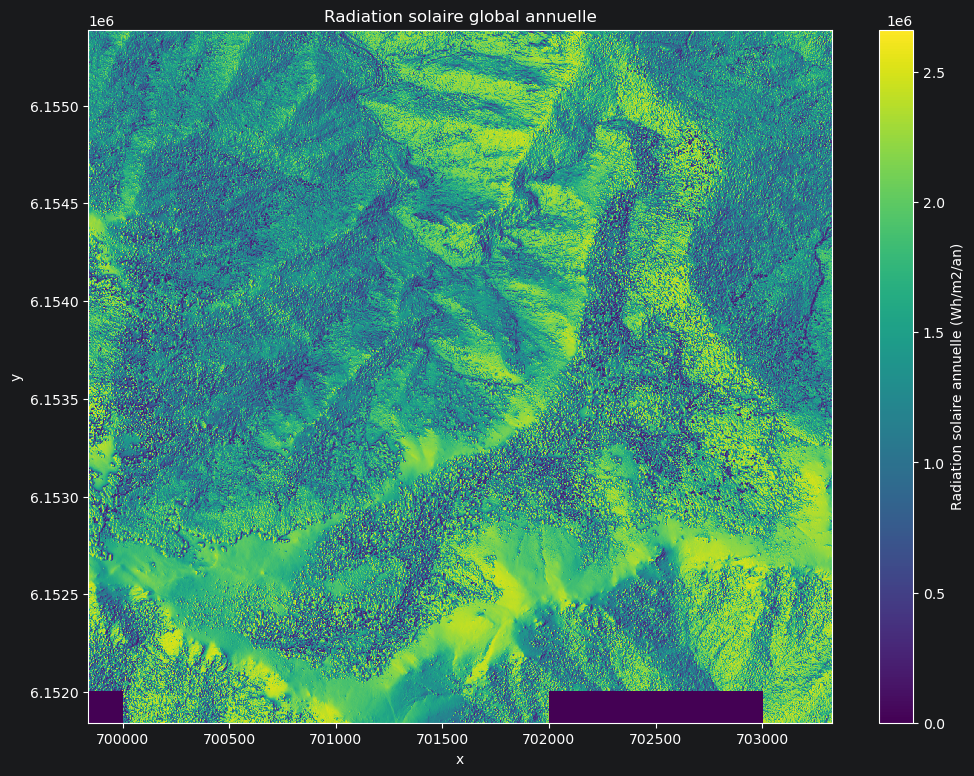

In [6]:
import matplotlib.pyplot as plt

rad_annual_sum_MNS.plot(
    figsize=(12, 9),
    cbar_kwargs={"label": "Radiation solaire annuelle (Wh/m2/an)"}
)

plt.title("Radiation solaire global annuelle")
plt.show()

In [17]:
# differences entre les 2 rasters

diff_pct = (
    (rad_annual_sum_MNS - rad_annual_sum_MNT)
    / rad_annual_sum_MNT
) * 100

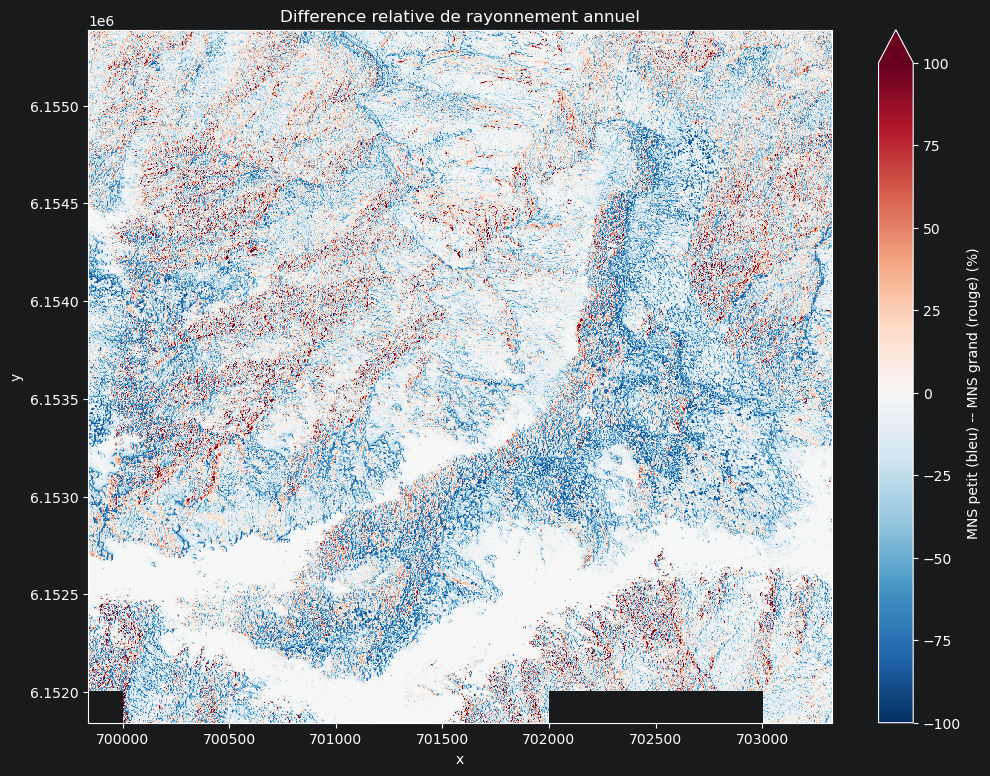

In [18]:
diff_pct.plot(
    figsize=(12, 9),
    cmap="RdBu_r",
    center=0,
    vmin=-100,
    vmax=100,
    cbar_kwargs={
        "label": "MNS petit (bleu) -- MNS grand (rouge) (%)"
    }
)

plt.title("Difference relative de rayonnement annuel")
plt.show()

In [8]:
oneday = rad_MNS["global_radiation"].sel(DOY=90)

Text(0.5, 1.0, 'Rayonnement journalier (Wh/m2/jour)')

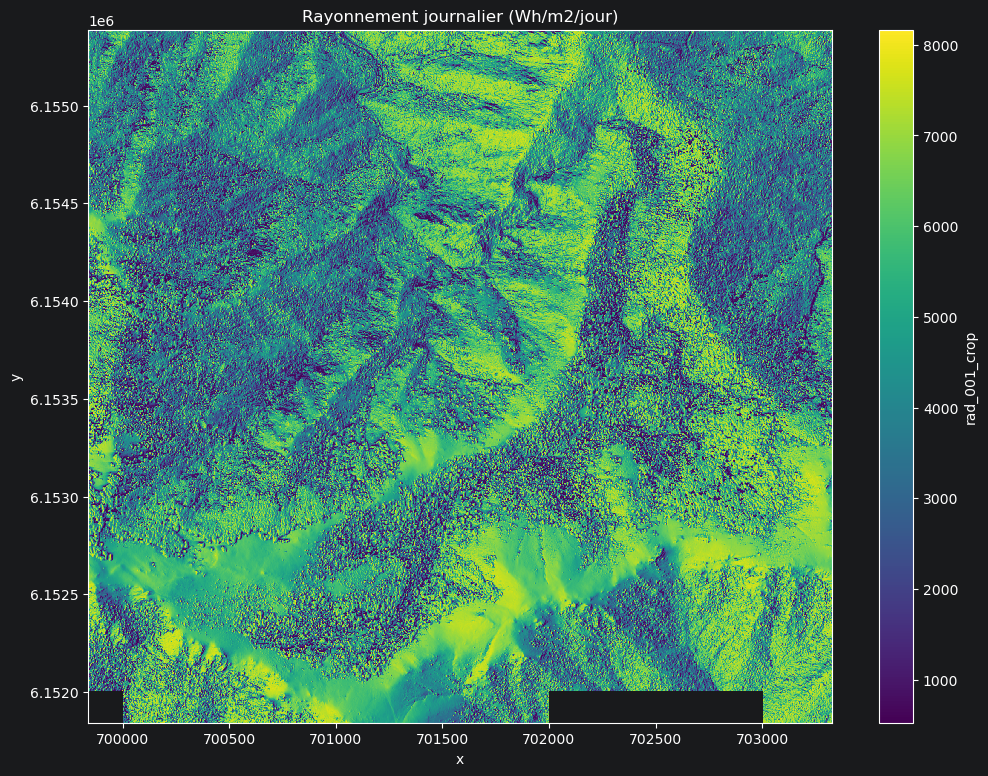

In [10]:
import matplotlib.pyplot as plt
oneday.plot(
    figsize=(12, 9),

)

plt.title("Rayonnement journalier (Wh/m2/jour)")